# Projeto da Disciplina — Introdução ao Aprendizado de Máquina

**Integrantes:** Debora Evleyn Lima Vicente, Gabriel Alves da Costa e Guilherme Marques Norbona

# Dataset 04 — Electricity

## Visão geral

Dados do mercado de eletricidade de New South Wales e Victoria, na Austrália. Cada registro representa um período de 30 minutos. O objetivo é classificar o preço de New South Wales em relação à média móvel recente.

- **Tarefa:** classificação binária com ordem temporal
- **Alvo:** `nsw_price_class`
- **Classes:** `up` e `down`
- **Atributos preditores:** 8

O alvo não indica diretamente se o preço futuro subirá ou cairá. Este conjunto deve ser tratado como benchmark histórico de classificação em fluxo e mudança de conceito.

## Arquivos

- `electricity_train.csv`: 36.240 registros iniciais da sequência.
- `electricity_test.csv`: 9.072 registros posteriores da sequência.

Os arquivos usam UTF-8, vírgula como separador e não possuem coluna de índice. A ordem das linhas e a divisão temporal fornecida devem ser preservadas.

## Distribuição das classes

| Conjunto | Registros | `down` | `up` |
| --- | ---: | ---: | ---: |
| Treino | 36.240 | 21.097 | 15.143 |
| Teste | 9.072 | 4.978 | 4.094 |

## Variáveis

| Variável | Tipo | Descrição |
| --- | --- | --- |
| `date_normalized` | numérica temporal | Representação normalizada da data. |
| `day` | categórica | Código do dia da semana, de `day_1` a `day_7`. |
| `period_index` | inteira temporal | Período de meia hora dentro do dia, de 1 a 48. |
| `nsw_price_normalized` | numérica | Preço normalizado em New South Wales. |
| `nsw_demand_normalized` | numérica | Demanda normalizada em New South Wales. |
| `vic_price_normalized` | numérica | Preço normalizado em Victoria. |
| `vic_demand_normalized` | numérica | Demanda normalizada em Victoria. |
| `transfer_normalized` | numérica | Transferência programada e normalizada entre os estados. |
| `nsw_price_class` | alvo | Estado `up` ou `down` do preço de NSW em relação à média móvel recente. |

## Orientações de uso

- Não substitua a divisão fornecida por uma separação aleatória: isso misturaria passado e futuro.
- Para ajuste de hiperparâmetros, use validação sequencial, como `TimeSeriesSplit`.
- `day` é uma categoria e `period_index` possui comportamento cíclico.
- As variáveis já foram normalizadas e não podem ser convertidas com segurança para as unidades econômicas originais.
- `date_normalized` possui repetições e algumas reduções ao longo da sequência; preserve a ordem original das linhas.
- Os dados cobrem o período de maio de 1996 a dezembro de 1998.

## Fonte e licença

OpenML — [Electricity, dataset 151](https://www.openml.org/d/151).

O campo de licença no OpenML está registrado como `Public`. Ao redistribuir ou adaptar os dados, mantenha a atribuição à fonte e aos autores.

Referência: Harries, M. (1999). *Splice-2 Comparative Evaluation: Electricity Pricing*. Technical Report, University of New South Wales.


In [1]:
### Versão do Python
# Versão da Linguagem Python
from platform import python_version
print('Versão da Linguagem Python Usada Neste Jupyter Notebook:', python_version())

Versão da Linguagem Python Usada Neste Jupyter Notebook: 3.11.18


In [2]:
# Imports
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import sklearn
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score, confusion_matrix
from sklearn.metrics import accuracy_score
%matplotlib inline 
import warnings
warnings.filterwarnings("ignore")

Matplotlib is building the font cache; this may take a moment.


In [3]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Debora Evleyn Lima Vicente, Gabriel Alves da Costa, Guilherme Marques Norbona" --iversions

Author: Debora Evleyn Lima Vicente, Gabriel Alves da Costa, Guilherme Marques Norbona

matplotlib: 3.10.3
numpy     : 1.26.0
pandas    : 2.3.1
seaborn   : 0.13.2
sklearn   : 1.7.2
xgboost   : 3.1.3



In [4]:
# Carrega os dados
dados_treino = pd.read_csv('dados/electricity_train.csv')
dados_teste = pd.read_csv("dados/electricity_test.csv")

In [5]:
# Shape
dados_teste.shape

(9072, 9)

In [6]:
# Colunas
dados_teste.columns

Index(['date_normalized', 'day', 'period_index', 'nsw_price_normalized',
       'nsw_demand_normalized', 'vic_price_normalized',
       'vic_demand_normalized', 'transfer_normalized', 'nsw_price_class'],
      dtype='object')

In [7]:
# Amostra dos dados
dados_treino.sample(10)

,date_normalized,day,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized,nsw_price_class
14615,0.433609,day_5,24,0.083283,0.526183,0.003467,0.422915,0.414912,up
24115,0.460732,day_7,20,0.051699,0.506248,0.003571,0.305800,0.319298,down
4595,0.013406,day_6,36,0.114567,0.602350,0.003467,0.422915,0.414912,up
15780,0.434671,day_1,37,0.056683,0.411038,0.003467,0.422915,0.414912,up
28942,0.474404,day_2,47,0.037108,0.365070,0.002565,0.230451,0.362281,down
2958,0.008849,day_7,31,0.041582,0.288753,0.003467,0.422915,0.414912,down
22696,0.456351,day_5,41,0.037679,0.665724,0.002493,0.554376,0.589474,up
31547,0.872307,day_1,12,0.012459,0.112467,0.000796,0.132056,0.797807,down
19852,0.447591,day_2,29,0.043533,0.543439,0.003207,0.573537,0.247368,down
20290,0.451086,day_4,35,0.047106,0.761827,0.003116,0.698343,0.356579,up


In [8]:
# Tipos de dados
dados_treino.dtypes

date_normalized          float64
day                       object
period_index               int64
nsw_price_normalized     float64
nsw_demand_normalized    float64
vic_price_normalized     float64
vic_demand_normalized    float64
transfer_normalized      float64
nsw_price_class           object
dtype: object

In [9]:
dados_teste.dtypes

date_normalized          float64
day                       object
period_index               int64
nsw_price_normalized     float64
nsw_demand_normalized    float64
vic_price_normalized     float64
vic_demand_normalized    float64
transfer_normalized      float64
nsw_price_class           object
dtype: object

## Duplicatas, valores faltantes e outliers

O enunciado do projeto informa que cada base da lista já é **pré-validada** pelo professor. Isso se confirma nos dados: como mostra a checagem abaixo, não há duplicatas nem valores faltantes em nenhum dos dois conjuntos. Por isso, tecnicamente não é necessário nenhum tratamento de limpeza nesta etapa — ainda assim, vale registrar a verificação e justificar a decisão sobre outliers, retomada com mais detalhe na Pergunta 8 da análise exploratória.

In [10]:
# Duplicatas e valores faltantes
print('Duplicatas - treino:', dados_treino.duplicated().sum(), '| teste:', dados_teste.duplicated().sum())
print()
print('Valores faltantes - treino:')
print(dados_treino.isnull().sum())
print()
print('Valores faltantes - teste:')
print(dados_teste.isnull().sum())

Duplicatas - treino: 0 | teste: 0

Valores faltantes - treino:
date_normalized          0
day                      0
period_index             0
nsw_price_normalized     0
nsw_demand_normalized    0
vic_price_normalized     0
vic_demand_normalized    0
transfer_normalized      0
nsw_price_class          0
dtype: int64

Valores faltantes - teste:
date_normalized          0
day                      0
period_index             0
nsw_price_normalized     0
nsw_demand_normalized    0
vic_price_normalized     0
vic_demand_normalized    0
transfer_normalized      0
nsw_price_class          0
dtype: int64


**Resultado:** zero duplicatas e zero valores faltantes nos dois conjuntos — não há o que tratar aqui.

Quanto a outliers, a decisão é **não remover nenhum valor**: as variáveis já chegam normalizadas pelo fornecedor (escala fixa, sem conversão para a unidade econômica original) e o alvo é definido em relação à média móvel recente do preço — remover os pontos extremos quebraria a sequência temporal e eliminaria picos de preço reais, que fazem parte do fenômeno. A Pergunta 8 da análise exploratória mostra essa inspeção em detalhe e os números que sustentam essa decisão.

In [11]:
dados_treino.sample(5)


,date_normalized,day,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized,nsw_price_class
31656,0.872395,day_3,25,0.032935,0.590152,0.002086,0.625583,0.537719,up
1180,0.001062,day_5,29,0.043983,0.447040,0.003467,0.422915,0.414912,down
11479,0.424494,day_3,8,0.055242,0.014430,0.003467,0.422915,0.414912,down
13856,0.429715,day_3,33,0.078960,0.614252,0.003467,0.422915,0.414912,up
34123,0.880890,day_5,44,0.026600,0.352871,0.001764,0.386328,0.594298,down


In [12]:
dados_teste.sample(5)

,date_normalized,day,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized,nsw_price_class
2618,0.894518,day_6,27,0.074457,0.636120,0.004987,0.668824,0.500439,up
1024,0.889961,day_1,17,0.028492,0.363285,0.001840,0.217245,0.758333,down
1496,0.893500,day_4,9,0.031434,0.279084,0.002011,0.380373,0.744737,down
6551,0.907349,day_4,24,0.055332,0.486165,0.003735,0.553599,0.427632,down
4734,0.902571,day_1,31,0.053050,0.235347,0.003529,0.258933,0.576316,down


In [13]:
dados_treino.rename({'nsw_price_class':'Target'}, axis = 'columns', inplace = True)
dados_teste.rename({'nsw_price_class':'Target'}, axis = 'columns', inplace = True)

In [14]:
dados_treino.sample(5)

,date_normalized,day,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized,Target
26999,0.469537,day_4,24,0.048607,0.520976,0.003232,0.487571,0.470614,up
30000,0.867838,day_4,1,0.028011,0.350491,0.000841,0.357846,0.661404,down
5385,0.014159,day_2,10,0.040651,0.198453,0.003467,0.422915,0.414912,down
8321,0.023008,day_7,18,0.089738,0.313746,0.003467,0.422915,0.414912,up
27758,0.473342,day_6,15,0.045184,0.510562,0.003105,0.498446,0.085526,up


In [15]:
dados_treino.describe(include = ['object'])

,day,Target
count,36240,36240
unique,7,2
top,day_2,down
freq,5184,21097


In [16]:
dados_treino.describe(exclude = ['object'])

,date_normalized,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized
count,36240.000000,36240.00000,36240.000000,36240.000000,36240.000000,36240.000000,36240.000000
mean,0.398356,24.50000,0.055556,0.416190,0.003216,0.412143,0.492504
std,0.306728,13.85359,0.037093,0.161215,0.010704,0.109486,0.151405
min,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.026724,12.75000,0.033505,0.301101,0.002181,0.383998,0.414912
50%,0.442945,24.50000,0.046836,0.434841,0.003467,0.422915,0.414912
75%,0.470023,36.25000,0.070614,0.527968,0.003467,0.422915,0.580702
max,0.995443,48.00000,1.000000,0.935733,1.000000,1.000000,1.000000


## Análise Exploratória

Organizamos a investigação em 8 perguntas sobre a base. Para cada uma, explicamos em uma frase o tipo de gráfico escolhido, respondemos com base no resultado e, ao final da seção, reunimos os achados e as limitações da base.

### Pergunta 1 — Qual é a faixa, a tendência central e a forma da distribuição de cada variável numérica?

Usamos um **histograma** para cada variável, pois ele mostra em uma única visualização a forma da distribuição (simetria, concentração, caudas) de todas as colunas numéricas.

In [17]:
dados_treino.describe()

,date_normalized,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized
count,36240.000000,36240.00000,36240.000000,36240.000000,36240.000000,36240.000000,36240.000000
mean,0.398356,24.50000,0.055556,0.416190,0.003216,0.412143,0.492504
std,0.306728,13.85359,0.037093,0.161215,0.010704,0.109486,0.151405
min,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.026724,12.75000,0.033505,0.301101,0.002181,0.383998,0.414912
50%,0.442945,24.50000,0.046836,0.434841,0.003467,0.422915,0.414912
75%,0.470023,36.25000,0.070614,0.527968,0.003467,0.422915,0.580702
max,0.995443,48.00000,1.000000,0.935733,1.000000,1.000000,1.000000


array([[<Axes: title={'center': 'date_normalized'}>,
        <Axes: title={'center': 'period_index'}>,
        <Axes: title={'center': 'nsw_price_normalized'}>],
       [<Axes: title={'center': 'nsw_demand_normalized'}>,
        <Axes: title={'center': 'vic_price_normalized'}>,
        <Axes: title={'center': 'vic_demand_normalized'}>],
       [<Axes: title={'center': 'transfer_normalized'}>, <Axes: >,
        <Axes: >]], dtype=object)

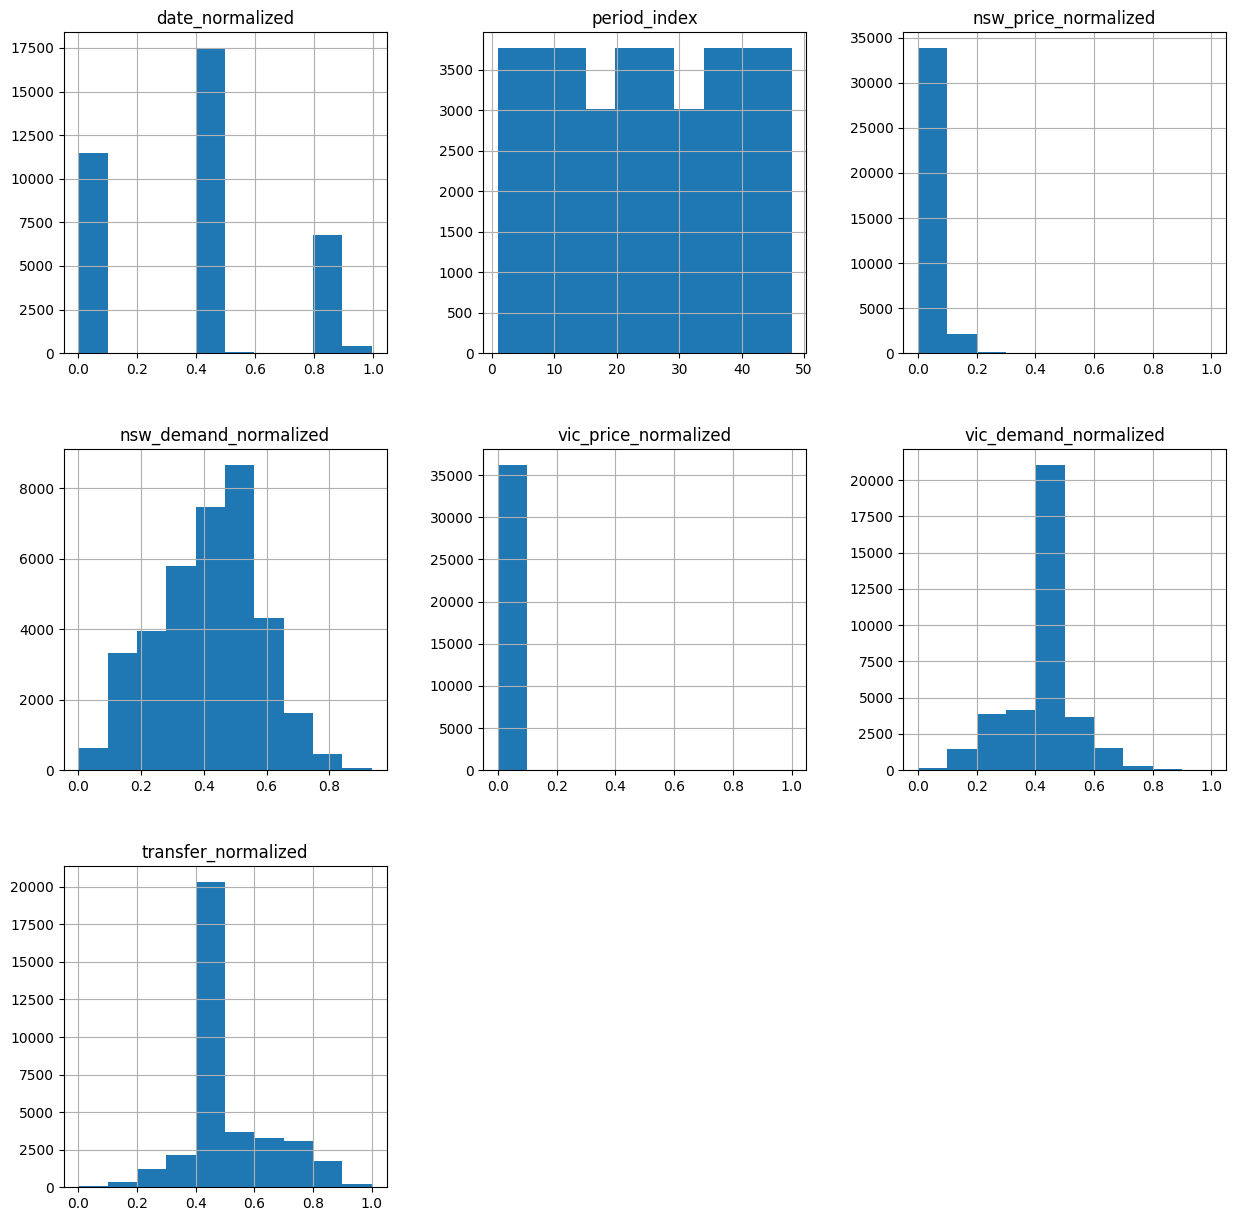

In [18]:
dados_treino.hist(figsize= (15,15), bins=10)

In [19]:
# Valores constantes no início da série: última linha do trecho em que a variável não muda
for col in ['vic_price_normalized', 'vic_demand_normalized', 'transfer_normalized']:
    inicial = dados_treino[col].iloc[0]
    tamanho = int((dados_treino[col] != inicial).to_numpy().argmax())
    print(f'{col}: constante ({inicial}) nas primeiras {tamanho} linhas ({100 * tamanho / len(dados_treino):.1f}% do treino); '
          f'no teste, esse valor aparece em {100 * (dados_teste[col] == inicial).mean():.2f}% das linhas')

vic_price_normalized: constante (0.003467) nas primeiras 17424 linhas (48.1% do treino); no teste, esse valor aparece em 0.02% das linhas
vic_demand_normalized: constante (0.422915) nas primeiras 17424 linhas (48.1% do treino); no teste, esse valor aparece em 0.00% das linhas
transfer_normalized: constante (0.414912) nas primeiras 17424 linhas (48.1% do treino); no teste, esse valor aparece em 0.35% das linhas


**Resposta:** `period_index` é uniforme (cada período do dia aparece o mesmo número de vezes). `date_normalized`, porém, **não** é uniforme: os valores se concentram em faixas separadas (quartis 0,027, 0,443 e 0,470), com intervalos vazios entre elas. `nsw_price_normalized` e `vic_price_normalized` são fortemente assimétricas à direita: a maior parte dos valores fica próxima da mediana, mas o máximo (1,0) está muito acima do percentil 99 (0,15 e 0,008, respectivamente) — ou seja, existem picos de preço raros e extremos. `nsw_demand_normalized` e `vic_demand_normalized` têm forma mais próxima de um sino, limitada entre 0 e 1. `transfer_normalized` tem um comportamento particular: quase metade dos registros do treino (≈48%) cai exatamente no mesmo valor (0,4149), formando um pico isolado no meio da distribuição. Como mostra a checagem acima, `vic_price_normalized`, `vic_demand_normalized` e `transfer_normalized` são constantes nas **primeiras 17.424 linhas** (48,1% do treino) e só depois passam a variar. Isso sugere preenchimento de dados indisponíveis nesse trecho, e não um estado real do mercado. No teste, esses valores praticamente não aparecem (no máximo 0,35% das linhas): há uma mudança clara de distribuição entre o início da série e o teste.

### Pergunta 2 — As classes do alvo estão balanceadas?

Usamos um **gráfico de barras (countplot)**, a forma padrão de comparar a contagem de categorias.

Número de vezes acima da média (up):  15143
Número de vezes abaixo da média (down):  21097


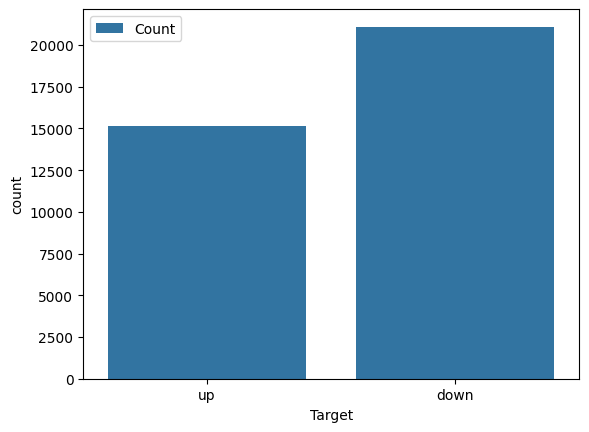

In [20]:
# Plot
sns.countplot(data = dados_treino, x = 'Target', label = 'Count')

# Value counts
contagem = dados_treino['Target'].value_counts()

# Print
print('Número de vezes acima da média (up): ', contagem['up'])
print('Número de vezes abaixo da média (down): ', contagem['down'])

**Resposta:** há um desequilíbrio moderado — no treino, 21.097 registros são `down` (≈58,2%) e 15.143 são `up` (≈41,8%). Não é severo a ponto de exigir reamostragem (como SMOTE), mas, para não favorecer a classe majoritária, aplicamos pesos de classe nos modelos que os aceitam. O desequilíbrio também justifica usar F1 e ROC_AUC além da acurácia, já que a acurácia isolada favoreceria um modelo que sempre prevê `down`.

### Pergunta 3 — O dia da semana (`day`) influencia a proporção de `up`/`down`? (relação entre variáveis)

Usamos um **gráfico de barras agrupado (countplot com `hue`)**, adequado para comparar a distribuição de uma variável categórica (`Target`) dentro das categorias de outra (`day`).

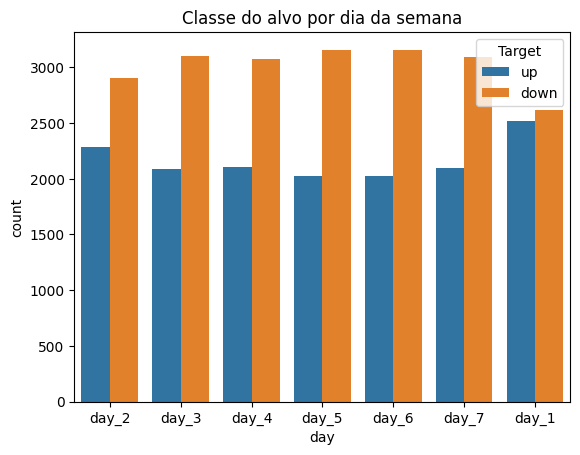

Target   down     up
day                 
day_1   50.95  49.05
day_2   55.96  44.04
day_3   59.76  40.24
day_4   59.32  40.68
day_5   60.88  39.12
day_6   60.96  39.04
day_7   59.61  40.39


In [21]:
# Proporção de up/down por dia da semana
sns.countplot(data=dados_treino, x='day', hue='Target')
plt.title('Classe do alvo por dia da semana')
plt.show()

print((pd.crosstab(dados_treino['day'], dados_treino['Target'], normalize='index') * 100).round(2))

**Resposta:** sim, há um efeito, embora moderado — a proporção de `up` varia de ≈49% no `day_1` até ≈39% no `day_5`/`day_6`. Isso é compatível com padrões de consumo de eletricidade que variam entre dias úteis e fim de semana, e justifica manter `day` como atributo categórico no modelo.

### Pergunta 4 — O período do dia (`period_index`) está relacionado ao preço médio de NSW? (relação entre variáveis)

Usamos um **gráfico de linha**, apropriado para mostrar como uma média varia ao longo de uma sequência ordenada (os 48 períodos de 30 minutos do dia).

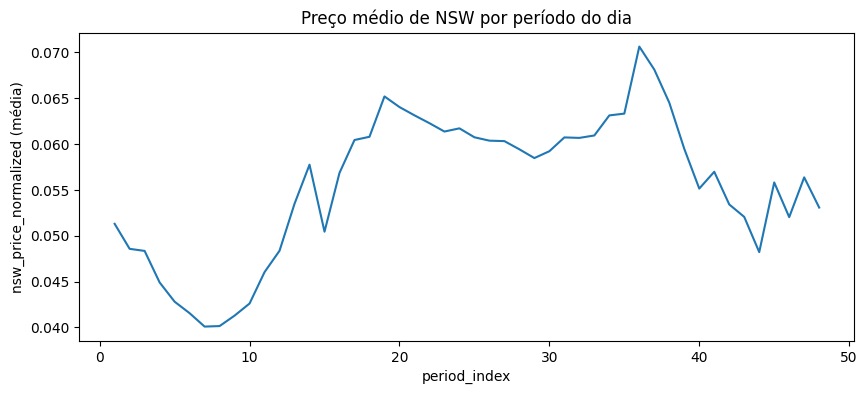

In [22]:
# Preço médio de NSW por período do dia
preco_por_periodo = dados_treino.groupby('period_index')['nsw_price_normalized'].mean()

plt.figure(figsize=(10, 4))
preco_por_periodo.plot()
plt.xlabel('period_index')
plt.ylabel('nsw_price_normalized (média)')
plt.title('Preço médio de NSW por período do dia')
plt.show()

**Resposta:** sim, há um padrão ao longo do dia: o preço médio vai de ≈0,040 (período 7) a ≈0,071 (período 36). A correlação linear é fraca (0,11), pois a relação não é linear. O horário também se associa à demanda, como mostra a correlação entre `period_index` e `nsw_demand_normalized` (0,45, calculada na Pergunta 5), o que é compatível com um efeito do horário sobre o preço passando pela demanda, embora a análise não prove causalidade.

### Pergunta 5 — Existe correlação entre as variáveis numéricas? (relação entre variáveis)

Usamos um **mapa de calor (heatmap)**, ideal para visualizar muitas correlações de uma vez, com a intensidade da cor indicando a força de cada relação.

In [23]:
dados_treino.corr(numeric_only=True)

,date_normalized,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized
date_normalized,1.000000e+00,-1.356108e-15,-0.328019,0.002621,-0.034109,-0.073681,0.482546
period_index,-1.356108e-15,1.000000e+00,0.106333,0.445710,0.016889,0.175581,-0.091737
nsw_price_normalized,-3.280192e-01,1.063327e-01,1.000000,0.268846,0.305123,0.277165,-0.348512
nsw_demand_normalized,2.620917e-03,4.457100e-01,0.268846,1.000000,0.064732,0.607151,-0.243363
vic_price_normalized,-3.410908e-02,1.688903e-02,0.305123,0.064732,1.000000,0.109223,-0.083104
vic_demand_normalized,-7.368113e-02,1.755814e-01,0.277165,0.607151,0.109223,1.000000,-0.560748
transfer_normalized,4.825457e-01,-9.173725e-02,-0.348512,-0.243363,-0.083104,-0.560748,1.000000


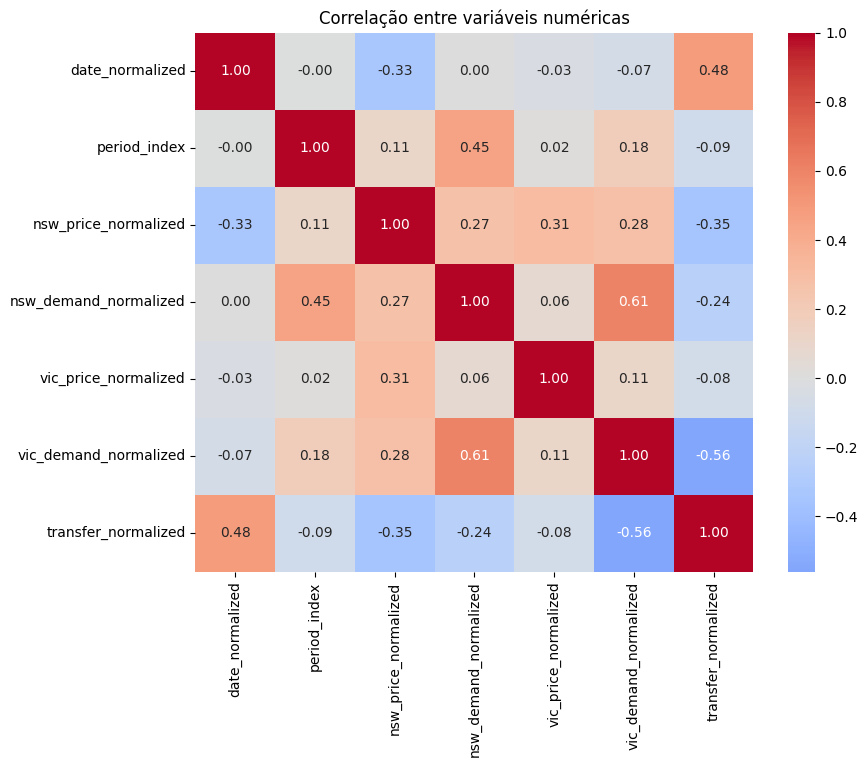

In [24]:
# Heatmap da matriz de correlação
plt.figure(figsize=(9, 7))
sns.heatmap(dados_treino.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlação entre variáveis numéricas')
plt.show()

**Resposta:** as correlações mais fortes são `vic_demand_normalized` × `nsw_demand_normalized` (0,61, positiva) e `vic_demand_normalized` × `transfer_normalized` (-0,56, negativa) — demanda nos dois estados anda junta, e quanto maior a demanda em Victoria, menor a transferência registrada. Já `nsw_price_normalized` (nosso principal preditor de interesse) tem correlação fraca a moderada com as outras (0,11 a 0,35 em módulo) — nenhuma variável isolada explica bem o preço, o que reforça a necessidade de um modelo multivariado.

**Ressalva:** as correlações que envolvem Victoria e a transferência são afetadas pelo trecho constante identificado na Pergunta 1. Considerando só as linhas posteriores a ele, a correlação entre as demandas dos dois estados sobe de 0,61 para 0,84.

### Pergunta 6 — O preço de NSW se relaciona com a transferência entre estados, considerando a classe do alvo? (relação entre variáveis)

Usamos um **gráfico de dispersão (scatter)** colorido pela classe do alvo, que permite ver ao mesmo tempo a relação entre duas variáveis contínuas e a separação entre as classes.

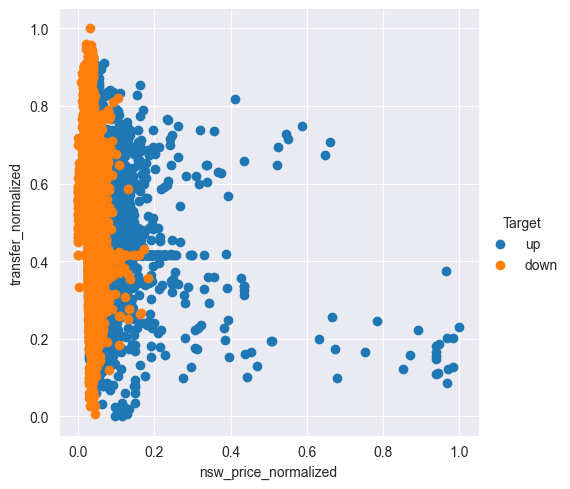

In [25]:
# Define o estilo do background
sns.set_style('darkgrid')  

# Facetgrid
sns.FacetGrid(dados_treino, hue = 'Target', height = 5).map(plt.scatter, 'nsw_price_normalized', 'transfer_normalized').add_legend()

**Resposta:** há uma sobreposição considerável entre as classes nesse par de variáveis — pontos `up` e `down` aparecem misturados na maior parte da nuvem, com uma tendência leve de preços mais altos (`nsw_price_normalized`) estarem mais associados a `up`. Como isoladamente essas duas variáveis não separam bem as classes, reforça a necessidade de combinar várias variáveis em um modelo multivariado.

### Pergunta 7 — A demanda de NSW varia conforme a classe do alvo? (relação entre variáveis)

Usamos um **boxplot**, apropriado para comparar a distribuição de uma variável numérica entre grupos categóricos (mediana, quartis e dispersão lado a lado).

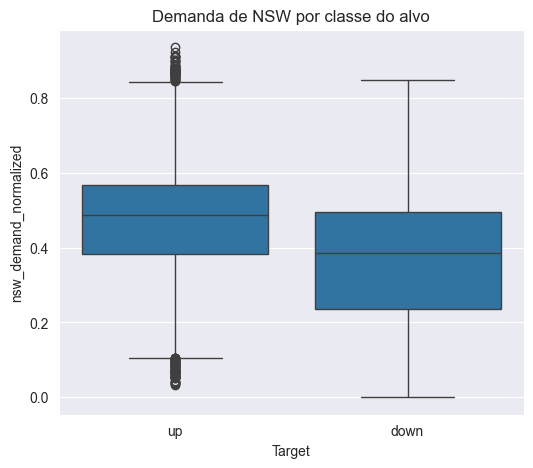

            mean       std       50%
Target                              
down    0.372003  0.161141  0.386790
up      0.477751  0.139695  0.487206


In [26]:
# Demanda de NSW por classe do alvo
plt.figure(figsize=(6, 5))
sns.boxplot(data=dados_treino, x='Target', y='nsw_demand_normalized')
plt.title('Demanda de NSW por classe do alvo')
plt.show()

print(dados_treino.groupby('Target')['nsw_demand_normalized'].describe()[['mean', 'std', '50%']])

**Resposta:** sim, e de forma clara — a demanda média de NSW é 0,478 quando o alvo é `up` e 0,372 quando é `down` (mediana 0,487 vs. 0,387). A diferença é clara, embora o preço de NSW separe ainda melhor as classes (mediana de 0,069 em `up` e 0,042 em `down`). Demandas maiores estão associadas a preços acima da média móvel recente, o que é coerente com a dinâmica real de mercados de eletricidade.

### Pergunta 8 — Existem outliers nas variáveis numéricas, e eles devem ser removidos?

Usamos **boxplots** e o critério do intervalo interquartil (IQR), a abordagem padrão para identificar outliers univariados.

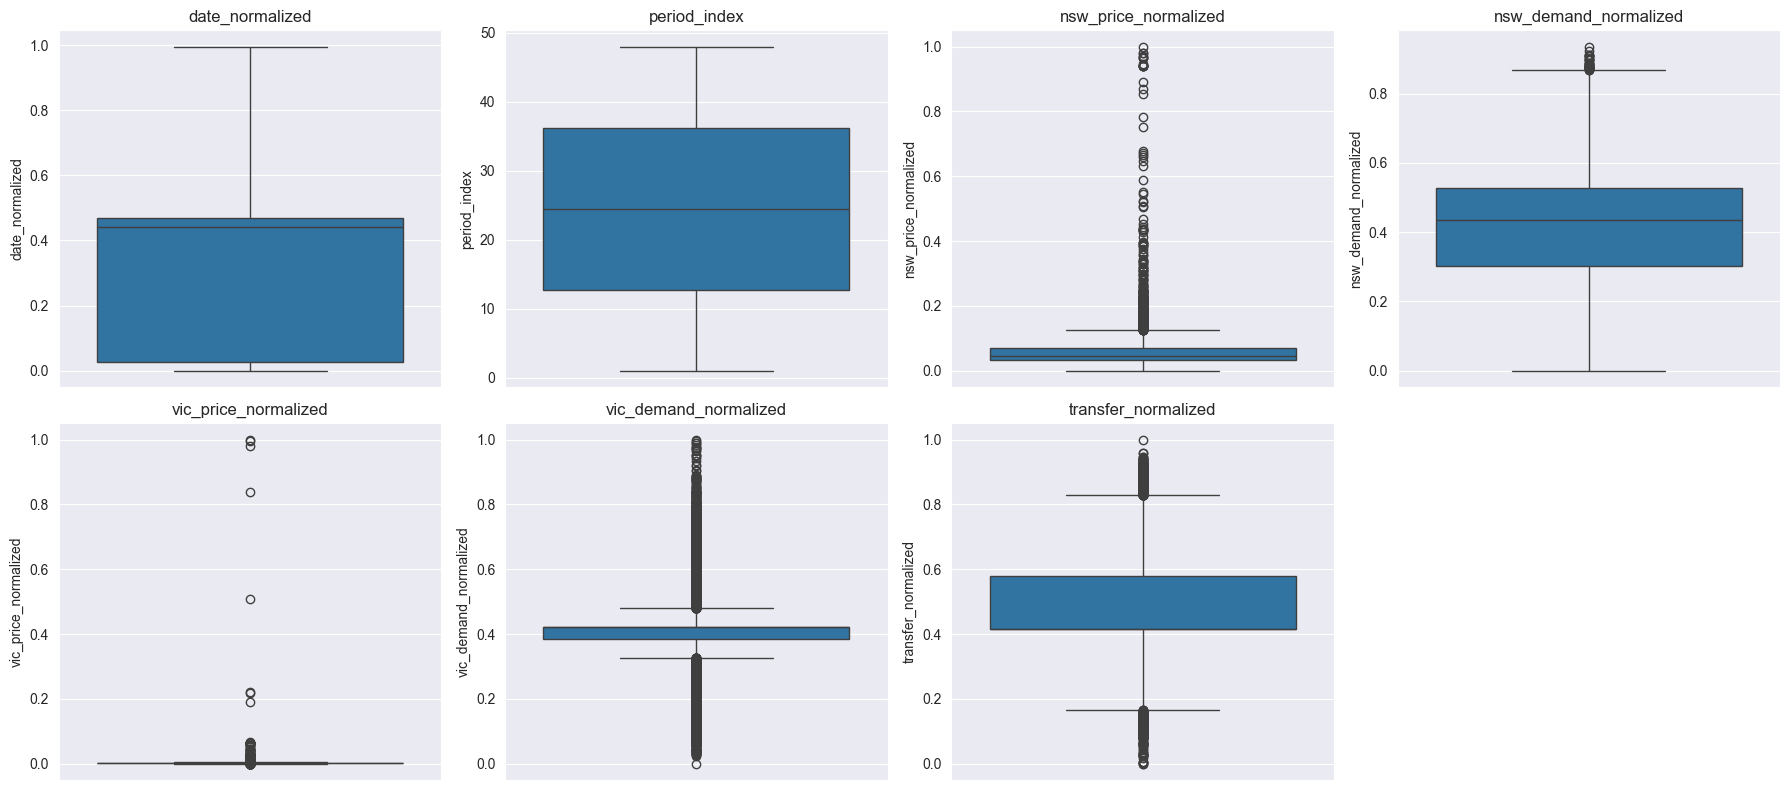

date_normalized: 0 outliers (0.00%)
period_index: 0 outliers (0.00%)
nsw_price_normalized: 723 outliers (2.00%)
nsw_demand_normalized: 33 outliers (0.09%)
vic_price_normalized: 1027 outliers (2.83%)
vic_demand_normalized: 12976 outliers (35.81%)
transfer_normalized: 1557 outliers (4.30%)


In [27]:
# Boxplots das variáveis numéricas
num_cols = ['date_normalized', 'period_index', 'nsw_price_normalized', 'nsw_demand_normalized',
            'vic_price_normalized', 'vic_demand_normalized', 'transfer_normalized']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=dados_treino, y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

# Contagem de outliers pelo critério do IQR (1.5x o intervalo interquartil)
for col in num_cols:
    q1, q3 = dados_treino[col].quantile(.25), dados_treino[col].quantile(.75)
    iqr = q3 - q1
    limite_baixo, limite_alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((dados_treino[col] < limite_baixo) | (dados_treino[col] > limite_alto)).sum()
    print(f'{col}: {n_outliers} outliers ({100 * n_outliers / len(dados_treino):.2f}%)')

**Resposta:** o critério de IQR encontra outliers em proporções muito diferentes entre as variáveis: 2,00% em `nsw_price_normalized`, 2,83% em `vic_price_normalized`, 4,30% em `transfer_normalized` e um surpreendente **35,81%** em `vic_demand_normalized`. Esse último número não é razoável — não é possível que mais de um terço dos registros sejam "atípicos". O motivo é o trecho constante visto na Pergunta 1: o valor repetido em 48% das linhas estreita artificialmente o intervalo interquartil e faz o critério classificar como "outlier" valores normais do restante da série. Nas linhas posteriores a esse trecho, a proporção cai para 0,18%. Combinado com o fato de que os preços já têm caudas longas **esperadas** (picos reais de preço de eletricidade), a decisão é **não remover nenhum outlier** — confirmando a justificativa dada no início do notebook.

### Síntese da análise exploratória

**Principais achados**
- O alvo é moderadamente desbalanceado (≈58% `down` / 42% `up`), tratado com pesos de classe e com o uso de F1 e ROC_AUC além da acurácia.
- `day` tem um efeito fraco a moderado sobre a proporção de `up`/`down` (Pergunta 3) — vale manter como atributo.
- `period_index` tem relação não linear com o preço e moderada com a demanda (Perguntas 4 e 5).
- Nenhuma variável isolada se correlaciona fortemente com o preço de NSW (Pergunta 5) nem separa bem as classes por si só (Pergunta 6) — reforça a escolha de modelos multivariados e não-lineares.
- `nsw_price_normalized` e `nsw_demand_normalized` são as variáveis com relação mais nítida com o alvo (Pergunta 7).
- Três variáveis são constantes nas primeiras 17.424 linhas do treino (Pergunta 1), o que torna o critério de IQR pouco confiável para outliers nesta base (Pergunta 8).

**Limitações da base**
- O alvo não indica diretamente se o preço vai subir no futuro — é definido pela relação com uma média móvel recente, o que dificulta uma leitura causal direta dos resultados.
- A série cobre maio de 1996 a dezembro de 1998 e está sujeita a mudança de conceito (*concept drift*) ao longo do tempo; padrões observados no início da série podem não se repetir no final.
- As variáveis já vêm normalizadas pelo fornecedor, sem possibilidade de reverter para as unidades econômicas originais (preço em moeda, demanda em MW etc.), o que limita a interpretação física dos valores.
- `date_normalized` tem repetições e reduções ao longo da sequência (conforme o README), então não pode ser tratada como um timestamp contínuo comum.
- Quase metade do treino traz valores constantes para Victoria e para a transferência, situação que praticamente não existe no teste.

## Preparação dos dados

Agora que a exploração inicial está feita, precisamos preparar os dados para o modelo:

1. Separar atributos (`X`) e alvo (`y`) em treino e teste;
2. Codificar o alvo `Target` (`down`/`up` → `0`/`1`);
3. Codificar a variável categórica `day` (One-Hot Encoding) e padronizar as numéricas;
4. Montar um pipeline de pré-processamento + modelo, ajustando (`fit`) **somente com o treino** — o teste só passa por `transform`.

A divisão treino/teste fornecida é temporal e é mantida como está (sem `train_test_split` aleatório).

In [28]:
# Separa atributos (X) e alvo (y) em treino e teste
X_train = dados_treino.drop(columns='Target')
y_train = dados_treino['Target']

X_test = dados_teste.drop(columns='Target')
y_test = dados_teste['Target']

print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_test: ', X_test.shape, '| y_test: ', y_test.shape)

X_train: (36240, 8) | y_train: (36240,)
X_test:  (9072, 8) | y_test:  (9072,)


In [29]:
from sklearn.preprocessing import LabelEncoder

# Codifica o alvo (down/up -> 0/1)
# Ajusta (fit) o encoder somente no treino; no teste, apenas aplica (transform)
codificador_alvo = LabelEncoder()
y_train = codificador_alvo.fit_transform(y_train)
y_test = codificador_alvo.transform(y_test)

print('Classes do alvo:', list(codificador_alvo.classes_))
print('Exemplo y_train:', y_train[:10])

Classes do alvo: ['down', 'up']
Exemplo y_train: [1 1 1 1 0 0 0 0 0 0]


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define quais colunas são numéricas e qual é a categórica
colunas_numericas = [
    'date_normalized', 'period_index', 'nsw_price_normalized',
    'nsw_demand_normalized', 'vic_price_normalized',
    'vic_demand_normalized', 'transfer_normalized'
]
colunas_categoricas = ['day']

# ColumnTransformer: padroniza as numéricas e aplica One-Hot na categórica
pre_processamento = ColumnTransformer([
    ('num', StandardScaler(), colunas_numericas),
    ('cat', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
])

In [31]:
len(X_train)

36240

In [32]:
len(X_test)

9072

In [33]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(36240, 8) (9072, 8) (36240,) (9072,)


In [34]:
X_train.head(2)

,date_normalized,day,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized
0,0.0,day_2,1,0.056443,0.439155,0.003467,0.422915,0.414912
1,0.0,day_2,2,0.051699,0.415055,0.003467,0.422915,0.414912


### Validação respeitando a ordem temporal

O README da base recomenda usar validação sequencial em vez do K-Fold padrão para a busca de hiperparâmetros, já que os dados têm ordem temporal. Por isso, usamos `TimeSeriesSplit` em toda busca de hiperparâmetros e validação cruzada deste notebook: cada divisão testa em um bloco que vem **depois** do bloco de treino, nunca embaralhando as linhas — evitando usar dados do "futuro" para ajustar hiperparâmetros que serão avaliados no "passado" dentro da própria validação.

### Métricas escolhidas

Usamos três métricas complementares:
- **Acurácia**: simples de interpretar, mas sensível ao desequilíbrio de classes (≈58%/42%, visto na EDA), por isso não é usada isoladamente.
- **F1**: equilibra precisão e recall da classe `up`, relevante porque errar um período acima da média móvel pode ter custo diferente de errar um período abaixo.
- **ROC_AUC**: mede a separação entre as classes independente do limiar de decisão escolhido; guia as buscas de hiperparâmetros (`scoring='roc_auc'`), exceto a escolha de `k` do KNN, feita por acurácia, e é usada no ranking final entre os modelos.

A busca de hiperparâmetros usa `GridSearchCV` na Regressão Logística e no SVM, e `RandomizedSearchCV` no Random Forest, na Árvore de Decisão e no XGBoost, sempre dentro de um `Pipeline` com o pré-processamento e sempre validando com `TimeSeriesSplit`.

In [35]:
from sklearn.model_selection import TimeSeriesSplit

# Validação sequencial: cada divisão treina em um bloco e testa no bloco seguinte,
# sem embaralhar as linhas, respeitando a ordem temporal da série
tscv = TimeSeriesSplit(n_splits=5)

## Modelo 1 - Regressão Logística (Benchmark)

In [36]:
from sklearn.pipeline import Pipeline

# Pipeline: pré-processamento (encoding/escala) + Regressão Logística
# class_weight='balanced' compensa o desequilíbrio moderado do alvo (≈58% down / ≈42% up, ver Pergunta 2)
pipeline_v1 = Pipeline([
    ('pre', pre_processamento),
    ('logistica', LogisticRegression(solver='liblinear', max_iter=1000, random_state=42, class_weight='balanced'))
])

# Define lista de hiperparâmetros (nomes prefixados com "logistica__" por estarem dentro do Pipeline)
# solver='liblinear' aceita tanto penalty 'l1' quanto 'l2'
tuned_params_v1 = {'logistica__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000],
                   'logistica__penalty': ['l1', 'l2']}

In [37]:
# Criaremos o modelo com GridSearch
# Vários modelos serão criados com diferentes combinações de hiperparâmetros
# Usa o pipeline_v1 (pré-processamento + logística) em vez da LogisticRegression bruta,
# para que a coluna categórica 'day' seja codificada antes do fit
modelo_v1 = GridSearchCV(pipeline_v1,
                         tuned_params_v1,
                         cv = tscv,
                         scoring = 'roc_auc',
                         n_jobs = -1)

In [38]:
modelo_v1.fit(X_train, y_train)

# Guarda o ROC_AUC médio da validação temporal (usa somente o treino)
cv_roc_v1 = modelo_v1.best_score_
print('ROC_AUC médio na validação:', cv_roc_v1)

ROC_AUC médio na validação: 0.8236756244257378


## Consolidando métricas — Modelo 1 (Regressão Logística)

Calculamos as métricas do Modelo 1 e criamos a tabela `df_modelos`, que vai acumular os resultados de cada modelo treinado.

In [39]:
# Previsões de classe e de probabilidade do Modelo 1
y_pred_v1 = modelo_v1.predict(X_test)
y_pred_proba_v1 = modelo_v1.predict_proba(X_test)[:, 1]

In [40]:
from sklearn.metrics import f1_score

# Métricas do Modelo 1
acuracia_v1 = accuracy_score(y_test, y_pred_v1)
f1_v1 = f1_score(y_test, y_pred_v1)
roc_auc_v1 = roc_auc_score(y_test, y_pred_proba_v1)

print('Acurácia:', acuracia_v1)
print('F1:', f1_v1)
print('ROC_AUC:', roc_auc_v1)

Acurácia: 0.6604938271604939
F1: 0.71047189321301
ROC_AUC: 0.8675555443462717


In [41]:
# Dicionário com as métricas do Modelo 1
dict_modelo_v1 = {'Modelo': 'Regressão Logística',
                   'Acurácia': acuracia_v1,
                   'F1': f1_v1,
                   'ROC_AUC': roc_auc_v1}

# Cria o dataframe que vai acumular as métricas de cada modelo
df_modelos = pd.DataFrame([dict_modelo_v1])
df_modelos

,Modelo,Acurácia,F1,ROC_AUC
0,Regressão Logística,0.660494,0.710472,0.867556


## Modelo 2 - Random Forest

In [42]:
# Pipeline: pré-processamento (encoding/escala) + Random Forest
# class_weight='balanced' compensa o desequilíbrio moderado do alvo (≈58% down / ≈42% up, ver Pergunta 2)
pipeline_v2 = Pipeline([
    ('pre', pre_processamento),
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

# Grid de hiperparâmetros (nomes prefixados com "rf__" por estarem dentro do Pipeline)
tuned_params_v2 = {'rf__n_estimators': [100, 200, 300, 400, 500],
                   'rf__min_samples_split': [2, 5, 10],
                   'rf__min_samples_leaf': [1, 2, 4]}

In [43]:
# Cria o modelo com RandomizedSearchCV para buscar a melhor combinação de hiperparâmetros
modelo_v2 = RandomizedSearchCV(pipeline_v2, 
                               tuned_params_v2, 
                               n_iter = 15, 
                               cv = tscv,
                               scoring = 'roc_auc', 
                               n_jobs  = -1,
                               random_state = 42)

In [44]:
# Treinamento do Modelo 2 (ajusta, fit, somente com o treino)
modelo_v2.fit(X_train, y_train)

# Guarda o ROC_AUC médio da validação temporal (usa somente o treino)
cv_roc_v2 = modelo_v2.best_score_
print('ROC_AUC médio na validação:', cv_roc_v2)

ROC_AUC médio na validação: 0.8164641401259773


In [45]:
modelo_v2.best_estimator_

,steps,"[('pre', ...), ('rf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [46]:
# Recria o modelo com os melhores hiperparâmetros encontrados, mantendo o pré-processamento
# (não pode ser o RandomForestClassifier puro, pois 'day' ainda é texto em X_train)
modelo_v2 = Pipeline([
    ('pre', pre_processamento),
    ('rf', RandomForestClassifier(n_estimators=500, min_samples_split=5, min_samples_leaf=4, random_state=42, class_weight='balanced'))
])
modelo_v2.fit(X_train, y_train)

,steps,"[('pre', ...), ('rf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [47]:
# Previsões de classe e de probabilidade do Modelo 2
# Usa modelo_v2 (RandomizedSearchCV já treinado), não pipeline_v2 (que nunca foi ajustado)
y_pred_v2 = modelo_v2.predict(X_test)
y_pred_proba_v2 = modelo_v2.predict_proba(X_test)[:, 1]

In [48]:
# Métricas do Modelo 2
acuracia_v2 = accuracy_score(y_test, y_pred_v2)
f1_v2 = f1_score(y_test, y_pred_v2)
roc_auc_v2 = roc_auc_score(y_test, y_pred_proba_v2)

print('Acurácia:', acuracia_v2)
print('F1:', f1_v2)
print('ROC_AUC:', roc_auc_v2)

Acurácia: 0.7227733686067019
F1: 0.7493771798704534
ROC_AUC: 0.8724517334012695


In [49]:
# Variáveis mais importantes do Random Forest
# feature_importances_ tem um valor por coluna DEPOIS do pré-processamento
# (one-hot expande 'day' em 7 colunas), por isso usamos get_feature_names_out()
# em vez de X_train.columns (que tem as colunas originais, antes do encoding)
rf_final = modelo_v2.named_steps['rf']
nomes_features = modelo_v2.named_steps['pre'].get_feature_names_out()
indices = np.argsort(-rf_final.feature_importances_)

print("Variáveis mais importantes para o resultado do modelo_v2:")
print(50 * "-")
for feature in nomes_features[indices]:
    print(feature)

Variáveis mais importantes para o resultado do modelo_v2:
--------------------------------------------------
num__nsw_price_normalized
num__date_normalized
num__nsw_demand_normalized
num__period_index
num__vic_price_normalized
num__vic_demand_normalized
num__transfer_normalized
cat__day_day_1
cat__day_day_2
cat__day_day_7
cat__day_day_4
cat__day_day_5
cat__day_day_3
cat__day_day_6


In [50]:
# Dicionário com as métricas do Modelo 2
dict_modelo_v2 = {'Modelo': 'Random Forest',
                   'Acurácia': acuracia_v2,
                   'F1': f1_v2,
                   'ROC_AUC': roc_auc_v2}

# Adiciona a linha do Modelo 2 ao dataframe de comparação
df_modelos = pd.concat([df_modelos, pd.DataFrame([dict_modelo_v2])], ignore_index=True)
df_modelos

,Modelo,Acurácia,F1,ROC_AUC
0,Regressão Logística,0.660494,0.710472,0.867556
1,Random Forest,0.722773,0.749377,0.872452


## Modelo 3 - KNN

In [51]:
# Pipeline: pré-processamento (encoding/escala) + KNN
# KNeighborsClassifier não tem o parâmetro class_weight (ele classifica pela maioria entre os vizinhos,
# não por um peso de classe no treino), então o KNN não recebe o balanceamento aplicado nos outros modelos
pipeline_v3 = Pipeline([
    ('pre', pre_processamento),
    ('knn', KNeighborsClassifier())
])

vizinhos = list(range(1, 20, 2))

In [52]:
cv_scores = []

In [53]:
# Validação cruzada para determinar o melhor valor de k
# Reaproveita o pipeline_v3 (pré-processamento + KNN), só muda o n_neighbors a cada
# iteração; usa tscv para respeitar a ordem temporal também na escolha de k
for k in vizinhos:
    pipeline_v3.set_params(knn__n_neighbors=k)
    scores = cross_val_score(pipeline_v3, X_train, y_train, cv = tscv, scoring = 'accuracy')
    cv_scores.append(scores.mean())   

In [54]:
# Ajustando o erro de classificação
erro = [1 - x for x in cv_scores]

In [55]:
# Determinando o melhor valor de k (com menor erro)
optimal_k = vizinhos[erro.index(min(erro))]
print('O valor ideal de k é %d' % optimal_k)

O valor ideal de k é 7


In [56]:
# Cria o modelo versão 3 com o melhor k encontrado, mantendo o pré-processamento
# (não pode ser o KNeighborsClassifier puro, pois 'day' ainda é texto em X_train)
modelo_v3 = Pipeline([
    ('pre', pre_processamento),
    ('knn', KNeighborsClassifier(n_neighbors = optimal_k))
])

# ROC_AUC médio da validação temporal (usa somente o treino)
cv_roc_v3 = cross_val_score(modelo_v3, X_train, y_train, cv = tscv, scoring = 'roc_auc').mean()
print('ROC_AUC médio na validação:', cv_roc_v3)

ROC_AUC médio na validação: 0.7085403896135253


In [57]:
# Treinamento do Modelo 3 (ajusta, fit, somente com o treino)
modelo_v3.fit(X_train, y_train)

,steps,"[('pre', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [58]:
# Previsões
y_pred_v3 = modelo_v3.predict(X_test)
y_pred_proba_v3 = modelo_v3.predict_proba(X_test)[:, 1]

In [59]:
# Métricas do Modelo 3
acuracia_v3 = accuracy_score(y_test, y_pred_v3)
f1_v3 = f1_score(y_test, y_pred_v3)
roc_auc_v3 = roc_auc_score(y_test, y_pred_proba_v3)

print('Acurácia:', acuracia_v3)
print('F1:', f1_v3)
print('ROC_AUC:', roc_auc_v3)

Acurácia: 0.7006172839506173
F1: 0.7014072119613016
ROC_AUC: 0.7691687587573894


In [60]:
# Dicionário com as métricas do Modelo 3
dict_modelo_v3 = {'Modelo': 'KNN',
                   'Acurácia': acuracia_v3,
                   'F1': f1_v3,
                   'ROC_AUC': roc_auc_v3}

# Adiciona a linha do Modelo 3 ao dataframe de comparação
df_modelos = pd.concat([df_modelos, pd.DataFrame([dict_modelo_v3])], ignore_index=True)
df_modelos

,Modelo,Acurácia,F1,ROC_AUC
0,Regressão Logística,0.660494,0.710472,0.867556
1,Random Forest,0.722773,0.749377,0.872452
2,KNN,0.700617,0.701407,0.769169


## Modelo 4 - Árvore de Decisão (Decision Tree)

In [61]:
# Pipeline: pré-processamento (encoding/escala) + Árvore de Decisão
# class_weight='balanced' compensa o desequilíbrio moderado do alvo (≈58% down / ≈42% up, ver Pergunta 2)
pipeline_v4 = Pipeline([
    ('pre', pre_processamento),
    ('arvore', DecisionTreeClassifier(random_state=42, class_weight='balanced'))
])

# Hiperparâmetros (nomes prefixados com "arvore__" por estarem dentro do Pipeline)
tuned_params_v4 = {'arvore__min_samples_split': [2, 3, 4, 5, 7],
                   'arvore__min_samples_leaf': [1, 2, 3, 4, 6],
                   'arvore__max_depth': [2, 3, 4, 5, 6, 7]}

In [62]:
modelo_v4 = RandomizedSearchCV(pipeline_v4,
                               tuned_params_v4,
                               n_iter = 15,
                               cv = tscv,
                               scoring= 'roc_auc',
                               n_jobs= -1,
                               random_state = 42)

In [63]:
# Treinamento do Modelo 4 (ajusta, fit, somente com o treino)
modelo_v4.fit(X_train, y_train)

# Guarda o ROC_AUC médio da validação temporal (usa somente o treino)
cv_roc_v4 = modelo_v4.best_score_
print('ROC_AUC médio na validação:', cv_roc_v4)

ROC_AUC médio na validação: 0.7826779474249194


In [64]:
modelo_v4.best_estimator_

,steps,"[('pre', ...), ('arvore', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [65]:
# Previsões de classe e de probabilidade do Modelo 4
y_pred_v4 = modelo_v4.predict(X_test)

In [66]:
# Previsões de probabilidade
y_pred_proba_v4 = modelo_v4.predict_proba(X_test)[:, 1]

In [67]:
confusion_matrix(y_test, y_pred_v4)

array([[3891, 1087],
       [ 771, 3323]], dtype=int64)

In [68]:
# Calcula ROC AUC score
roc_auc_v4 = roc_auc_score(y_test, y_pred_v4)
print(roc_auc_v4)

0.7966574176989403


In [69]:
fpr_v4, tpr_v4, thresholds = roc_curve(y_test, y_pred_proba_v4)

In [70]:
# AUC
auc_v4 = auc(fpr_v4, tpr_v4)
print(auc_v4)

0.8554358032205407


In [71]:
# Calcula acurácia
acuracia_v4 = accuracy_score(y_test, y_pred_v4)
print(acuracia_v4)

0.7951940035273368


## Feature Importance

In [72]:
modelo_v4 = Pipeline([
    ('pre', pre_processamento),
    ('arvore', DecisionTreeClassifier(min_samples_split=3, min_samples_leaf=4, max_depth=7, random_state=42, class_weight='balanced'))
])
modelo_v4.fit(X_train, y_train)

,steps,"[('pre', ...), ('arvore', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [73]:
# Variáveis mais importantes da Árvore de Decisão
# feature_importances_ tem um valor por coluna DEPOIS do pré-processamento
# (one-hot expande 'day' em 7 colunas), por isso usamos get_feature_names_out()
# em vez de X_train.columns (que tem as colunas originais, antes do encoding)
arvore_final = modelo_v4.named_steps['arvore']
nomes_features = modelo_v4.named_steps['pre'].get_feature_names_out()
indices = np.argsort(-arvore_final.feature_importances_)

print("Variáveis mais importantes para o resultado do modelo_v4:")
print(50 * "-")
for feature in nomes_features[indices]:
    print(feature)

Variáveis mais importantes para o resultado do modelo_v4:
--------------------------------------------------
num__nsw_price_normalized
num__date_normalized
num__nsw_demand_normalized
num__period_index
cat__day_day_1
cat__day_day_4
num__vic_price_normalized
cat__day_day_3
cat__day_day_2
num__vic_demand_normalized
cat__day_day_7
num__transfer_normalized
cat__day_day_6
cat__day_day_5


In [74]:
# Métricas do Modelo 4
acuracia_v4 = accuracy_score(y_test, y_pred_v4)
f1_v4 = f1_score(y_test, y_pred_v4)
roc_auc_v4 = roc_auc_score(y_test, y_pred_proba_v4)

print('Acurácia:', acuracia_v4)
print('F1:', f1_v4)
print('ROC_AUC:', roc_auc_v4)

Acurácia: 0.7951940035273368
F1: 0.7815145813734713
ROC_AUC: 0.8554358032205407


In [75]:
# Dicionário com as métricas do Modelo 4
dict_modelo_v4 = {'Modelo': 'Árvore de Decisão',
                   'Acurácia': acuracia_v4,
                   'F1': f1_v4,
                   'ROC_AUC': roc_auc_v4}

# Adiciona a linha do Modelo 4 ao dataframe de comparação
df_modelos = pd.concat([df_modelos, pd.DataFrame([dict_modelo_v4])], ignore_index=True)
df_modelos

,Modelo,Acurácia,F1,ROC_AUC
0,Regressão Logística,0.660494,0.710472,0.867556
1,Random Forest,0.722773,0.749377,0.872452
2,KNN,0.700617,0.701407,0.769169
3,Árvore de Decisão,0.795194,0.781515,0.855436


## Modelo 5 - SVM

Mesmo padrão dos outros modelos: pipeline de pré-processamento + SVM, com `GridSearchCV` buscando os melhores valores de `C` e `gamma` (kernel RBF). Depois extraímos os melhores hiperparâmetros com `best_params_` e recriamos o modelo final com `probability=True`, para usar `predict_proba` no cálculo do ROC_AUC, assim como nos outros modelos.

In [76]:
# Pipeline: pré-processamento (encoding/escala) + SVM
# class_weight='balanced' compensa o desequilíbrio moderado do alvo (≈58% down / ≈42% up, ver Pergunta 2)
pipeline_v5 = Pipeline([
    ('pre', pre_processamento),
    ('svm', SVC(kernel='rbf', random_state=42, class_weight='balanced'))
])

# Grade de hiperparâmetros (nomes prefixados com "svm__" por estarem dentro do Pipeline)
tuned_params_v5 = {'svm__C': [0.001, 0.01, 0.1, 1, 10],
                   'svm__gamma': [0.001, 0.01, 0.1, 1]}

In [77]:
# Cria o modelo com GridSearchCV para buscar a melhor combinação de hiperparâmetros
modelo_v5 = GridSearchCV(pipeline_v5,
                         tuned_params_v5,
                         cv = tscv,
                         scoring = 'roc_auc',
                         n_jobs = -1)

In [78]:
modelo_v5

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'svm__C': [0.001, 0.01, ...], 'svm__gamma': [0.001, 0.01, ...]}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [79]:
# Treinamento do Modelo 5 (ajusta, fit, somente com o treino)
modelo_v5.fit(X_train, y_train)

# Guarda o ROC_AUC médio da validação temporal (usa somente o treino)
cv_roc_v5 = modelo_v5.best_score_
print('ROC_AUC médio na validação:', cv_roc_v5)

ROC_AUC médio na validação: 0.817135571947528


In [80]:
modelo_v5.best_estimator_

,steps,"[('pre', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
# Extrai os melhores hiperparâmetros encontrados pelo GridSearchCV
# best_params_ devolve um dicionário com as chaves prefixadas (ex.: 'svm__C'),
# pois os hiperparâmetros pertencem à etapa 'svm' dentro do Pipeline
melhores_params_v5 = modelo_v5.best_params_
print(melhores_params_v5)

{'svm__C': 1, 'svm__gamma': 0.001}


In [82]:
# Recria o modelo com os melhores hiperparâmetros encontrados, mantendo o pré-processamento
# (não pode ser o SVC puro, pois 'day' ainda é texto em X_train)
# probability=True habilita o predict_proba, como nos outros modelos
# class_weight='balanced' compensa o desequilíbrio moderado do alvo (≈58% down / ≈42% up, ver Pergunta 2)
modelo_v5 = Pipeline([
    ('pre', pre_processamento),
    ('svm', SVC(C=melhores_params_v5['svm__C'],
                gamma=melhores_params_v5['svm__gamma'],
                kernel='rbf', probability=True, random_state=42, class_weight='balanced'))
])
modelo_v5.fit(X_train, y_train)

,steps,"[('pre', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [83]:
# Previsões de classe e de probabilidade do Modelo 5
y_pred_v5 = modelo_v5.predict(X_test)

In [84]:
y_pred_proba_v5 = modelo_v5.predict_proba(X_test)[:, 1]

In [85]:
confusion_matrix(y_test, y_pred_v5)

array([[1920, 3058],
       [ 166, 3928]], dtype=int64)

In [86]:
# Métricas do Modelo 5
acuracia_v5 = accuracy_score(y_test, y_pred_v5)
f1_v5 = f1_score(y_test, y_pred_v5)
roc_auc_v5 = roc_auc_score(y_test, y_pred_proba_v5)

print('Acurácia:', acuracia_v5)
print('F1:', f1_v5)
print('ROC_AUC:', roc_auc_v5)

Acurácia: 0.644620811287478
F1: 0.7090252707581227
ROC_AUC: 0.8782115416283038


In [87]:
# Dicionário com as métricas do Modelo 5
dict_modelo_v5 = {'Modelo': 'SVM (RBF)',
                   'Acurácia': acuracia_v5,
                   'F1': f1_v5,
                   'ROC_AUC': roc_auc_v5}

# Adiciona a linha do Modelo 5 ao dataframe de comparação
df_modelos = pd.concat([df_modelos, pd.DataFrame([dict_modelo_v5])], ignore_index=True)
df_modelos

,Modelo,Acurácia,F1,ROC_AUC
0,Regressão Logística,0.660494,0.710472,0.867556
1,Random Forest,0.722773,0.749377,0.872452
2,KNN,0.700617,0.701407,0.769169
3,Árvore de Decisão,0.795194,0.781515,0.855436
4,SVM (RBF),0.644621,0.709025,0.878212


## Modelo 6 - XGBoost (ponto extra)

Mesmo padrão dos outros modelos: pipeline de pré-processamento + XGBoost, com `RandomizedSearchCV` buscando os melhores valores de `n_estimators`, `max_depth` e `learning_rate`. Usamos `scale_pos_weight` para compensar o desequilíbrio de classes, equivalente ao `class_weight='balanced'` usado nos outros modelos (o XGBoost não tem esse parâmetro). Modelo adicional, implementado para o ponto extra da rubrica de avaliação da disciplina. A escolha se justifica por ser um método de *boosting*, que combina árvores em sequência, cada uma corrigindo os erros das anteriores — abordagem diferente do Random Forest, que combina árvores independentes.

In [88]:
# Peso para compensar o desequilíbrio de classes (down=0 é majoritária, up=1 é minoritária, ver Pergunta 2)
# Equivalente ao class_weight='balanced' usado nos outros modelos: o XGBoost não tem esse parâmetro,
# usa scale_pos_weight (razão entre a contagem da classe negativa e da positiva)
peso_balanceamento_v6 = (y_train == 0).sum() / (y_train == 1).sum()

# Pipeline: pré-processamento (encoding/escala) + XGBoost
pipeline_v6 = Pipeline([
    ('pre', pre_processamento),
    ('xgb', XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=peso_balanceamento_v6))
])

# Grade de hiperparâmetros (nomes prefixados com "xgb__" por estarem dentro do Pipeline)
tuned_params_v6 = {'xgb__n_estimators': [100, 200, 300, 400, 500],
                   'xgb__max_depth': [2, 3, 4, 5, 6],
                   'xgb__learning_rate': [0.01, 0.05, 0.1, 0.2]}

In [89]:
# Cria o modelo com RandomizedSearchCV para buscar a melhor combinação de hiperparâmetros
modelo_v6 = RandomizedSearchCV(pipeline_v6,
                               tuned_params_v6,
                               n_iter = 15,
                               cv = tscv,
                               scoring = 'roc_auc',
                               n_jobs = -1,
                               random_state = 42)

In [90]:
# Treinamento do Modelo 6 (ajusta, fit, somente com o treino)
modelo_v6.fit(X_train, y_train)

# Guarda o ROC_AUC médio da validação temporal (usa somente o treino)
cv_roc_v6 = modelo_v6.best_score_
print('ROC_AUC médio na validação:', cv_roc_v6)

ROC_AUC médio na validação: 0.8379239408973339


In [91]:
modelo_v6.best_estimator_

,steps,"[('pre', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [92]:
# Extrai os melhores hiperparâmetros encontrados pelo RandomizedSearchCV
melhores_params_v6 = modelo_v6.best_params_
print(melhores_params_v6)

{'xgb__n_estimators': 400, 'xgb__max_depth': 2, 'xgb__learning_rate': 0.1}


In [93]:
# Recria o modelo com os melhores hiperparâmetros encontrados, mantendo o pré-processamento
# (não pode ser o XGBClassifier puro, pois 'day' ainda é texto em X_train)
modelo_v6 = Pipeline([
    ('pre', pre_processamento),
    ('xgb', XGBClassifier(n_estimators=melhores_params_v6['xgb__n_estimators'],
                           max_depth=melhores_params_v6['xgb__max_depth'],
                           learning_rate=melhores_params_v6['xgb__learning_rate'],
                           random_state=42, eval_metric='logloss',
                           scale_pos_weight=peso_balanceamento_v6))
])
modelo_v6.fit(X_train, y_train)

,steps,"[('pre', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [94]:
# Variáveis mais importantes do XGBoost
# feature_importances_ tem um valor por coluna DEPOIS do pré-processamento
# (one-hot expande 'day' em 7 colunas), por isso usamos get_feature_names_out()
# em vez de X_train.columns (que tem as colunas originais, antes do encoding)
xgb_final = modelo_v6.named_steps['xgb']
nomes_features = modelo_v6.named_steps['pre'].get_feature_names_out()
indices = np.argsort(-xgb_final.feature_importances_)

print("Variáveis mais importantes para o resultado do modelo_v6:")
print(50 * "-")
for feature in nomes_features[indices]:
    print(feature)

Variáveis mais importantes para o resultado do modelo_v6:
--------------------------------------------------
num__nsw_price_normalized
num__nsw_demand_normalized
num__period_index
num__vic_price_normalized
num__date_normalized
cat__day_day_1
cat__day_day_2
cat__day_day_7
num__transfer_normalized
num__vic_demand_normalized
cat__day_day_5
cat__day_day_4
cat__day_day_3
cat__day_day_6


In [95]:
# Previsões de classe e de probabilidade do Modelo 6
y_pred_v6 = modelo_v6.predict(X_test)
y_pred_proba_v6 = modelo_v6.predict_proba(X_test)[:, 1]

print(y_pred_v6)
print(y_pred_proba_v6)

[1 1 1 ... 0 1 1]
[0.84487885 0.8251945  0.8989039  ... 0.1664405  0.7773336  0.6647346 ]


In [96]:
# Métricas do Modelo 6
acuracia_v6 = accuracy_score(y_test, y_pred_v6)
f1_v6 = f1_score(y_test, y_pred_v6)
roc_auc_v6 = roc_auc_score(y_test, y_pred_proba_v6)

print('Acurácia:', acuracia_v6)
print('F1:', f1_v6)
print('ROC_AUC:', roc_auc_v6)

Acurácia: 0.7075617283950617
F1: 0.7415489527520701
ROC_AUC: 0.8711737114726388


In [97]:
# Dicionário com as métricas do Modelo 6
dict_modelo_v6 = {'Modelo': 'XGBoost',
                   'Acurácia': acuracia_v6,
                   'F1': f1_v6,
                   'ROC_AUC': roc_auc_v6}

# Adiciona a linha do Modelo 6 ao dataframe de comparação
df_modelos = pd.concat([df_modelos, pd.DataFrame([dict_modelo_v6])], ignore_index=True)
df_modelos

,Modelo,Acurácia,F1,ROC_AUC
0,Regressão Logística,0.660494,0.710472,0.867556
1,Random Forest,0.722773,0.749377,0.872452
2,KNN,0.700617,0.701407,0.769169
3,Árvore de Decisão,0.795194,0.781515,0.855436
4,SVM (RBF),0.644621,0.709025,0.878212
5,XGBoost,0.707562,0.741549,0.871174


## Comparação final entre os modelos

In [98]:
# Ordena os modelos pelo ROC_AUC (métrica global, ideal para comparar algoritmos diferentes)
df_modelos_final = df_modelos.sort_values('ROC_AUC', ascending=False).reset_index(drop=True)
df_modelos_final

,Modelo,Acurácia,F1,ROC_AUC
0,SVM (RBF),0.644621,0.709025,0.878212
1,Random Forest,0.722773,0.749377,0.872452
2,XGBoost,0.707562,0.741549,0.871174
3,Regressão Logística,0.660494,0.710472,0.867556
4,Árvore de Decisão,0.795194,0.781515,0.855436
5,KNN,0.700617,0.701407,0.769169


In [99]:
# ROC_AUC médio na validação temporal (treino) ao lado das métricas de teste
cv_roc = {'Regressão Logística': cv_roc_v1, 'Random Forest': cv_roc_v2, 'KNN': cv_roc_v3,
          'Árvore de Decisão': cv_roc_v4, 'SVM (RBF)': cv_roc_v5, 'XGBoost': cv_roc_v6}
df_modelos_final.insert(1, 'ROC_AUC validação', df_modelos_final['Modelo'].map(cv_roc))
df_modelos_final = df_modelos_final.rename(columns={'Acurácia': 'Acurácia teste', 'F1': 'F1 teste', 'ROC_AUC': 'ROC_AUC teste'})
df_modelos_final

,Modelo,ROC_AUC validação,Acurácia teste,F1 teste,ROC_AUC teste
0,SVM (RBF),0.817136,0.644621,0.709025,0.878212
1,Random Forest,0.816464,0.722773,0.749377,0.872452
2,XGBoost,0.837924,0.707562,0.741549,0.871174
3,Regressão Logística,0.823676,0.660494,0.710472,0.867556
4,Árvore de Decisão,0.782678,0.795194,0.781515,0.855436
5,KNN,0.708540,0.700617,0.701407,0.769169


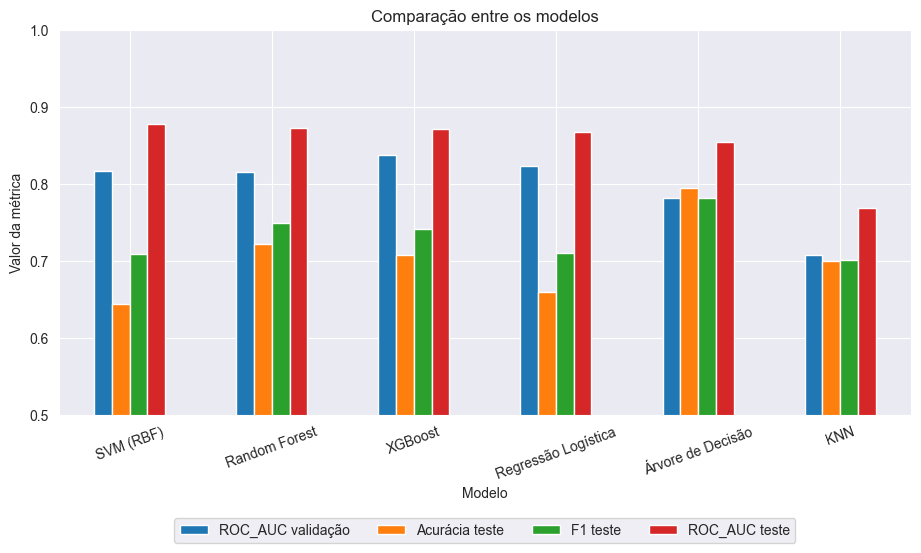

In [100]:
# Comparação visual das métricas
df_modelos_final.set_index('Modelo').plot(kind='bar', figsize=(11, 5), rot=20)
plt.ylim(0.5, 1)
plt.title('Comparação entre os modelos')
plt.ylabel('Valor da métrica')
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.35), ncol=4)
plt.show()

### Referência ingênua (persistência)

Como a série é temporal, comparamos também com uma regra sem aprendizado: repetir a classe do período imediatamente anterior. A comparação não é direta, porque a regra usa o rótulo do período anterior, informação que os seis modelos não recebem.

In [101]:
# Persistência: prevê, para cada período de teste, a classe observada no período anterior
y_anterior = np.concatenate(([y_train[-1]], y_test[:-1]))
print('Acurácia:', accuracy_score(y_test, y_anterior))
print('F1:', f1_score(y_test, y_anterior))

Acurácia: 0.8484347442680776
F1: 0.8320918305043351


## Interpretação dos resultados

- **Validação:** pela validação temporal, que usa somente o treino, o **XGBoost** tem o maior ROC_AUC (0,838), seguido de **Regressão Logística** (0,824), **SVM** (0,817), **Random Forest** (0,816), **Árvore de Decisão** (0,783) e **KNN** (0,709). Como a escolha do modelo não deve se basear no teste, o XGBoost é o modelo selecionado.
- **Teste:** os ROC_AUC dos quatro primeiros são próximos: **SVM** (0,878), **Random Forest** (0,872), **XGBoost** (0,871) e **Regressão Logística** (0,868). Depois vêm a **Árvore de Decisão** (0,855) e o **KNN** (0,769). A ordem muda em relação à validação, e diferenças tão pequenas não permitem afirmar que um deles é superior.
- **Limiar de decisão:** o caso extremo é o **SVM**: recall de 95,9% para `up`, com precisão de só 56,2%, o que leva a acurácia a 0,645. Ordenar bem os casos (ROC_AUC) não garante boas decisões no limiar padrão.
- **Acurácia e F1:** a **Árvore de Decisão** tem os maiores valores no teste (0,795 e 0,782). O **Random Forest** (0,723 e 0,749) fica um pouco acima do **XGBoost** (0,708 e 0,742).
- **Variáveis:** `nsw_price_normalized` é a mais importante no Random Forest, na Árvore e no XGBoost; `nsw_demand_normalized`, `date_normalized` e `period_index` também aparecem entre as cinco primeiras nos três.
- **Referência ingênua:** repetir a classe do período anterior acerta 84,8% (F1 de 0,832), acima de todos os modelos no limiar padrão. A comparação não é direta, pois a regra usa um rótulo que os modelos não recebem, mas mostra que a classe é muito persistente no tempo.
- **No contexto do problema:** se o objetivo é não perder períodos acima da média móvel, o **SVM** é muito sensível, com muitos alarmes falsos. Se o objetivo é acertar a classe no limiar padrão, a **Árvore de Decisão** foi a melhor no teste. Se o limiar puder ser ajustado, SVM, Random Forest, XGBoost e Regressão Logística oferecem separação parecida.

## Limitações e possíveis melhorias

**Limitações**
- Três variáveis são constantes em 48,1% do treino, situação que praticamente não ocorre no teste.
- A série está sujeita a mudança de conceito, e os modelos são treinados uma única vez.
- `period_index` é cíclico, mas foi tratado como numérico comum.
- `date_normalized` tem papel relevante nos modelos, embora não seja um relógio contínuo.
- O `k` do KNN foi escolhido por acurácia, critério diferente do usado nos demais modelos, e o KNN não recebe pesos de classe.
- O melhor `gamma` do SVM está no limite inferior da grade testada.

**Possíveis melhorias**
- Incluir a classe e o preço de períodos anteriores como atributos, se essa informação estiver disponível no momento da previsão.
- Codificar `period_index` com seno e cosseno.
- Ajustar o limiar de decisão na validação temporal.
- Comparar o treino completo com o treino sem o trecho de valores constantes.
- Usar retreinamento periódico ou aprendizado em fluxo para lidar com a mudança de conceito.